# The Joys of Seaborn and Squarify
Three visualizations built from the provided data sets: a heatmap (`heatmap.csv`), a violin plot (`violin_plot.csv`), and a tree map (`tree_map.csv`).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import squarify

sns.set_theme(style='white', font_scale=1.05)

## 1. Heatmap: 2024 graduates by degree type and program
Sequential palette (`YlGnBu`): darker cells = more graduates. Programs are sorted from most to fewest total graduates, and degree types run from shortest to longest credential.

In [2]:
grads = pd.read_csv('heatmap.csv')
print(grads.shape)
grads.head()

(747, 6)


,Graduate ID,Gender,Age,Race,Degree Type,Degree Program
0,1,Female,36,Hispanic or Latino,Certificate,Business
1,2,Female,28,White,Certificate,Business
2,3,Female,31,White,Associate's,Business
3,4,Female,32,Black or African American,Associate's,Computer Science
4,5,Female,20,Asian,Bachelor's,Business


In [3]:
degree_order = ['Certificate', "Associate's", "Bachelor's", "Master's"]
table = pd.crosstab(grads['Degree Program'], grads['Degree Type'])[degree_order]
table = table.loc[table.sum(axis=1).sort_values(ascending=False).index]
print('Total graduates:', table.values.sum())
table

Total graduates: 747


Degree Type,Certificate,Associate's,Bachelor's,Master's
Degree Program,,,,
Information Technology,20,23,62,34
Finance,17,20,56,19
Computer Science,15,12,50,30
Film,12,15,42,28
Statistics,10,15,40,30
Business,10,10,39,31
History,6,8,9,9
Philosophy,4,8,6,10
Health Science,4,5,8,10


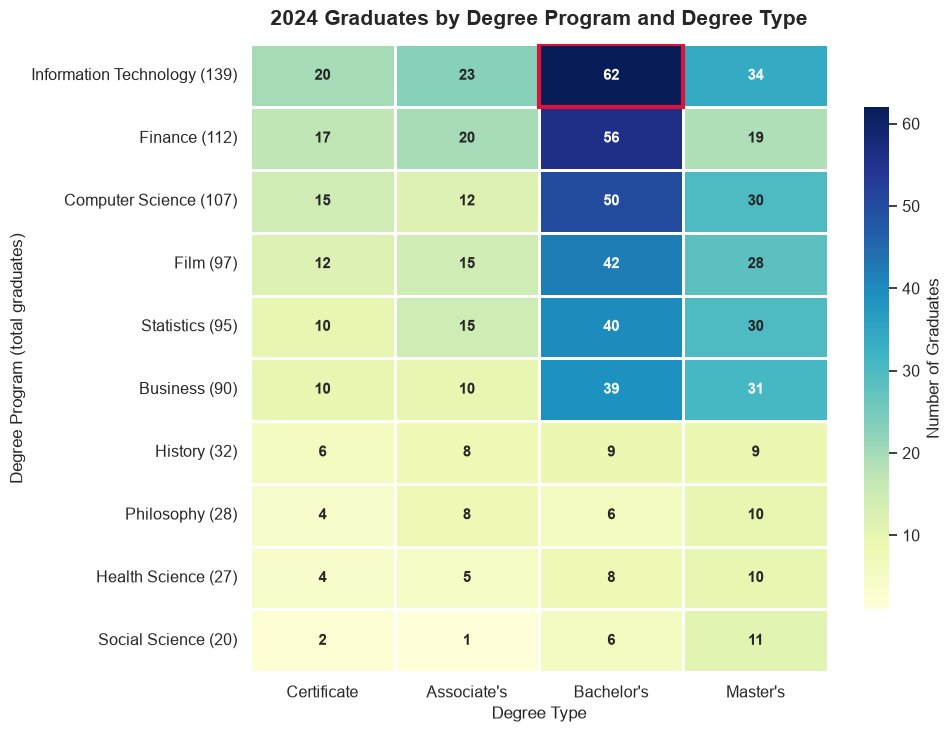

In [4]:
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(table, cmap='YlGnBu', annot=True, fmt='d', linewidths=1, linecolor='white',
            annot_kws={'fontsize': 11, 'fontweight': 'bold'},
            cbar_kws={'label': 'Number of Graduates', 'shrink': 0.8}, ax=ax)

# Outline the single largest cell
r, c = divmod(table.values.argmax(), table.shape[1])
ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor='crimson', linewidth=3))

# Show each program's total in its row label
ax.set_yticklabels([f'{p} ({t})' for p, t in zip(table.index, table.sum(axis=1))], rotation=0)

ax.set_title('2024 Graduates by Degree Program and Degree Type', fontsize=15, fontweight='bold', pad=14)
ax.set_xlabel('Degree Type', fontsize=12)
ax.set_ylabel('Degree Program (total graduates)', fontsize=12)
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('heatmap_graduates.png', dpi=150, bbox_inches='tight')
plt.show()

In [5]:
print('Graduates by degree type:'); print(table.sum().to_string())
print('\nShare of graduates earning a Bachelor\'s: {:.1%}'.format(table["Bachelor's"].sum() / table.values.sum()))
print('Largest cell:', table.index[r], '/', table.columns[c], '=', table.iloc[r, c])

Graduates by degree type:
Degree Type
Certificate    100
Associate's    117
Bachelor's     318
Master's       212

Share of graduates earning a Bachelor's: 42.6%
Largest cell: Information Technology / Bachelor's = 62


## 2. Violin plot: guest experience scores by Disney World theme park
Scores are whole numbers from 1 to 10, so `cut=0` keeps the density curves from extending past the real scale. Parks are ordered from highest to lowest median score. Inner lines show quartiles, and white diamonds mark the mean.

In [6]:
parks = pd.read_csv('violin_plot.csv')
print(parks.shape)
parks.groupby('Theme Park')['Score'].describe().round(2)

(400, 2)


,count,mean,std,min,25%,50%,75%,max
Theme Park,,,,,,,,
Animal Kingdom,100.0,5.17,2.76,1.0,3.0,5.0,8.0,10.0
Epcot,100.0,5.97,2.24,1.0,5.0,6.0,7.0,10.0
Hollywood Studios,100.0,4.76,2.30,1.0,3.0,5.0,6.0,10.0
Magic Kingdom,100.0,7.35,2.57,1.0,6.0,8.0,9.0,10.0


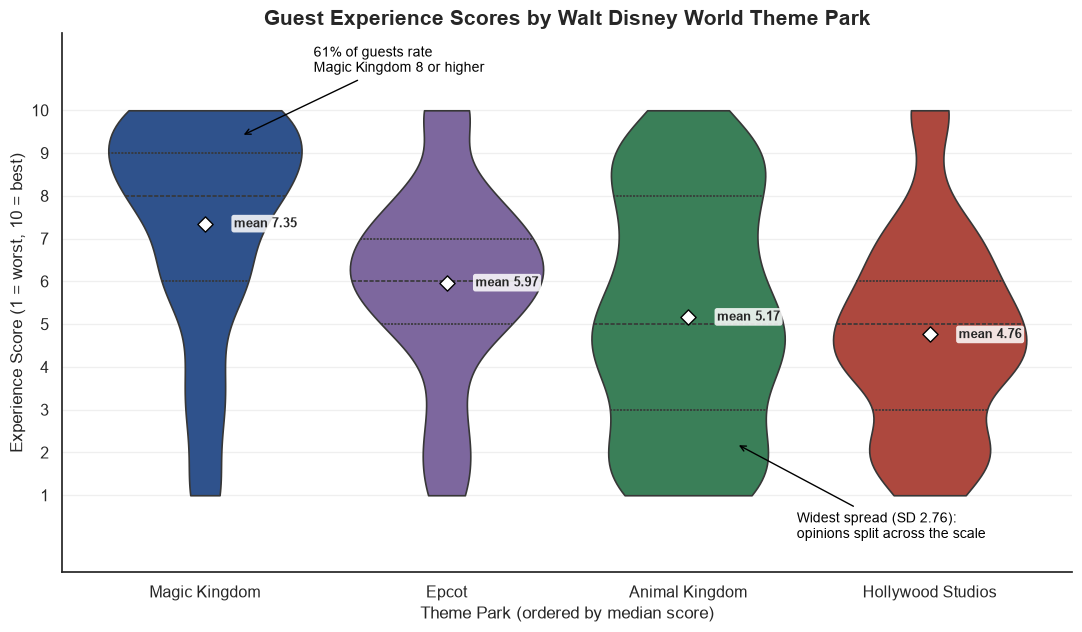

In [7]:
order = parks.groupby('Theme Park')['Score'].median().sort_values(ascending=False).index
means = parks.groupby('Theme Park')['Score'].mean()
palette = {'Magic Kingdom': '#1f4e9c', 'Epcot': '#7b5ea7', 'Animal Kingdom': '#2e8b57', 'Hollywood Studios': '#c0392b'}

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.violinplot(data=parks, x='Theme Park', y='Score', hue='Theme Park', order=order, palette=palette,
               inner='quart', cut=0, bw_adjust=0.8, linewidth=1.2, legend=False, ax=ax)
for i, park in enumerate(order):
    ax.scatter(i, means[park], marker='D', s=60, color='white', edgecolor='black', zorder=5)
    ax.text(i + 0.12, means[park], f'mean {means[park]:.2f}', va='center', fontsize=9, fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='white', edgecolor='none', alpha=0.85))

ax.annotate('61% of guests rate\nMagic Kingdom 8 or higher', xy=(0.15, 9.4), xytext=(0.45, 10.9),
            arrowprops=dict(arrowstyle='->', color='black'), fontsize=10, color='black')
ax.annotate('Widest spread (SD 2.76):\nopinions split across the scale', xy=(2.2, 2.2), xytext=(2.45, 0.0),
            arrowprops=dict(arrowstyle='->', color='black'), fontsize=10, color='black')

ax.set_title('Guest Experience Scores by Walt Disney World Theme Park', fontsize=15, fontweight='bold')
ax.set_xlabel('Theme Park (ordered by median score)', fontsize=12)
ax.set_ylabel('Experience Score (1 = worst, 10 = best)', fontsize=12)
ax.set_yticks(range(1, 11))
ax.set_ylim(-0.8, 11.8)
ax.grid(axis='y', alpha=0.3)
sns.despine(ax=ax, top=True, right=True)
plt.tight_layout()
plt.savefig('violin_theme_parks.png', dpi=150, bbox_inches='tight')
plt.show()

In [8]:
summary = parks.groupby('Theme Park')['Score'].agg(
    median='median', mean='mean', std='std',
    pct_8_plus=lambda s: (s >= 8).mean() * 100,
    pct_4_or_less=lambda s: (s <= 4).mean() * 100).round(2)
summary.loc[order]

,median,mean,std,pct_8_plus,pct_4_or_less
Theme Park,,,,,
Magic Kingdom,8.0,7.35,2.57,61.0,16.0
Epcot,6.0,5.97,2.24,21.0,19.0
Animal Kingdom,5.0,5.17,2.76,26.0,43.0
Hollywood Studios,5.0,4.76,2.30,10.0,47.0


## 3. Tree map: share of films by genre
Each box shows the genre and its percentage of the 5,000 films (based on count). Boxes are sorted largest to smallest.

In [9]:
films = pd.read_csv('tree_map.csv')
print(films.shape, '| Years:', films['Year'].min(), '-', films['Year'].max())
films.head()

(5000, 7) | Years: 1915 - 2025


,Movie Title,Year,Directors,Writers,Rating,Runtime,Genre
0,The Shawshank Redemption,1994,Frank Darabont,"Stephen King, Frank Darabont",9.3,142,Drama
1,The Godfather,1972,Francis Ford Coppola,"Mario Puzo, Francis Ford Coppola",9.2,175,Crime
2,The Dark Knight,2008,Christopher Nolan,"Jonathan Nolan, Christopher Nolan, David S. Go...",9.0,152,Action
3,The Lord of the Rings: The Return of the King,2003,Peter Jackson,"J.R.R. Tolkien, Fran Walsh, Philippa Boyens, P...",9.0,201,Adventure
4,Schindler's List,1993,Steven Spielberg,"Thomas Keneally, Steven Zaillian",9.0,195,Biography


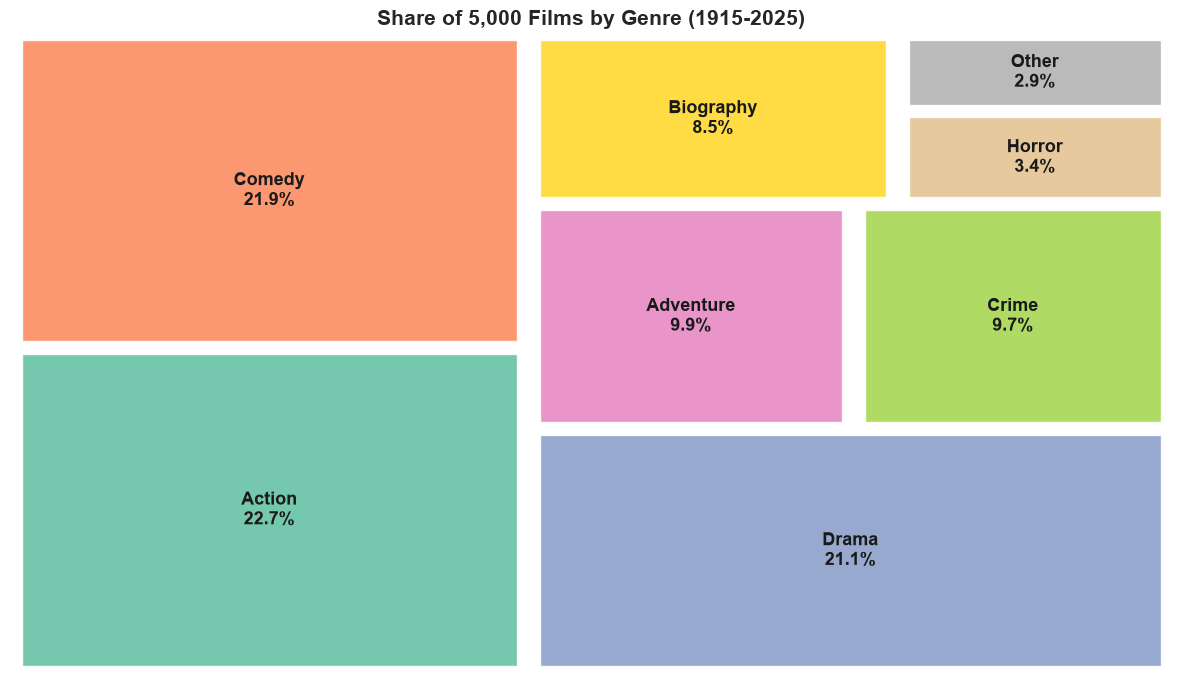

In [10]:
genre_counts = films['Genre'].value_counts()
pct = genre_counts / genre_counts.sum() * 100
labels = [f'{g}\n{p:.1f}%' for g, p in zip(genre_counts.index, pct)]
colors = sns.color_palette('Set2', len(genre_counts))

fig, ax = plt.subplots(figsize=(12, 7))
squarify.plot(sizes=genre_counts.values, label=labels, color=colors, alpha=0.9, pad=True,
              text_kwargs={'fontsize': 13, 'fontweight': 'bold', 'color': '#1a1a1a'}, ax=ax)
ax.set_title(f'Share of {genre_counts.sum():,} Films by Genre ({films["Year"].min()}-{films["Year"].max()})',
             fontsize=15, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.savefig('treemap_film_genres.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
pd.DataFrame({'films': genre_counts, 'percent': pct.round(1)})

,films,percent
Genre,,
Action,1133,22.7
Comedy,1097,21.9
Drama,1055,21.1
Adventure,493,9.9
Crime,484,9.7
Biography,423,8.5
Horror,171,3.4
Other,144,2.9
